In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt

## Implementing ViT in pytorch
While ready-made implementations exist, this is an attempt to build ViT from scratch using the basic building blocks from pytorch

torch.Size([1, 3, 128, 128])


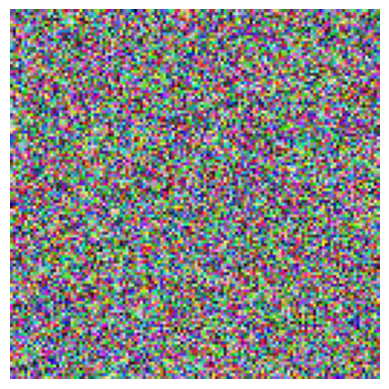

In [3]:
# Image --Patchify--> Patches --Tokenizer--> Tokens --PosEncoding--> Tokens --Embedding--> Embedded vectors --Encoder(self-attn)--> Latent vector --FFN--> Class
image = np.random.randint(0, 255, (128, 128, 3))
image_tensor = torch.tensor(image, dtype=torch.uint8).unsqueeze(0).permute(0,3,1,2)
plt.axis("off")
plt.imshow(image)
print(image_tensor.shape)

In [4]:
# Patchify
device = "cuda" if torch.cuda.is_available() else "cpu"
image_tensor = image_tensor.float() / 255.0
image_tensor.to(device)
patchify = torch.nn.Unfold(16, stride=16)
patches = patchify(image_tensor)
patches = patches.permute(0,2,1) # B, flatten_len, num_patches -> B, num_patches, flatten_len
print(patches.shape, image_tensor.shape, patches.dtype)

torch.Size([1, 64, 768]) torch.Size([1, 3, 128, 128]) torch.float32


In [5]:
# Linear embedding and positional encoding
linear_embed = torch.nn.Linear(768, 767) # Input -> Embed_dim
pos_embed = torch.zeros((1,65), dtype=torch.float32)
pos_embed = torch.arange(0, 65, 1, out=pos_embed, dtype=torch.float32).unsqueeze(2) # (B, pos_embed_size, num_patches)
embedded_patches = linear_embed(patches)
# Add cls_token
cls_token = torch.zeros((1,1,767), dtype=torch.float32)
embedded_patches = torch.concat([cls_token, embedded_patches], dim=1)
print(embedded_patches.shape)
# Append pos_embed
embeddings = torch.concat([embedded_patches, pos_embed], dim=2)
print(embeddings.shape)

torch.Size([1, 65, 767])
torch.Size([1, 65, 768])


In [6]:
from torch.nn import functional as F
from torch import Tensor
from collections.abc import Callable
from typing import Union

class TransformerEncoder(torch.nn.Module):
    def __init__(self, num_layers: int, num_classes: int, embed_dim: int = 768, num_heads=4, norm_first:bool=True, activation: Union[str, Callable[[Tensor], Tensor]] = F.gelu ,*args, **kwargs) -> None:
        super().__init__(*args, **kwargs)
        self.num_classes = num_classes
        self.embed_dim = embed_dim
        layers = [torch.nn.TransformerEncoderLayer(embed_dim, num_heads, batch_first=True, norm_first=norm_first) for _ in range(num_layers)]
        
        self.encoder_blocks = torch.nn.Sequential(*layers)

    def forward(self, x):
        x = self.encoder_blocks(x)
        cls = x[:,0]
        final_layer = torch.nn.Linear(self.embed_dim, self.num_classes)
        out = final_layer(cls)

        return torch.nn.functional.softmax(out, dim = 1)
        
transformer_enc = TransformerEncoder(3, 10)
latent_vec = transformer_enc(embeddings)
print(latent_vec.shape, latent_vec)
transformer_enc

torch.Size([1, 10]) tensor([[0.1040, 0.0606, 0.0808, 0.0456, 0.0511, 0.1154, 0.1264, 0.1478, 0.1592,
         0.1092]], grad_fn=<SoftmaxBackward0>)


TransformerEncoder(
  (encoder_blocks): Sequential(
    (0): TransformerEncoderLayer(
      (self_attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
      )
      (linear1): Linear(in_features=768, out_features=2048, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (linear2): Linear(in_features=2048, out_features=768, bias=True)
      (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout1): Dropout(p=0.1, inplace=False)
      (dropout2): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerEncoderLayer(
      (self_attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
      )
      (linear1): Linear(in_features=768, out_features=2048, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (linear2): Linear(in_features=2048, o

We can go one step finer and use `torch.nn.MultiHeadAttention` or go even further and implement attention layers as well. But let us first clean up the current implementation into a single class and check its performance on MNIST.

In [ ]:
class ViT(torch.nn.Module):
    def __init__(self, num_layers: int, num_classes: int, embed_dim: int = 768, num_heads: int =4, patch_size: int = 16, norm_first:bool=True, activation: Union[str, Callable[[Tensor], Tensor]] = F.gelu, *args, **kwargs) -> None:
        super().__init__(*args, **kwargs)
        self.num_layers = num_layers
        self.num_classes = num_classes
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.patch_size = patch_size
        self.patchify = torch.nn.Unfold(patch_size, stride=patch_size)
        self.linear_embed = torch.nn.Linear(self.patch_size**2 * 3, self.patch_size**2 * 3 - 1) # Input -> Embed_dim

        self.layers = [torch.nn.TransformerEncoderLayer(self.embed_dim, self.num_heads, activation=activation, norm_first=norm_first, batch_first=True) for _ in range(self.num_layers)]
        self.last_layer = torch.nn.Linear(self.embed_dim, self.num_classes)
        self.layers.append(self.last_layer)

    def embed(self, img):
        h, w = img.shape[-2:]
        if h%self.patch_size != 0 or w%self.patch_size != 0:
            raise Exception("Image shape is not compatible with patch size")
        patches = self.patchify(img)
        patches = patches.permute(0,2,1) # B, flatten_len, num_patches -> B, num_patches, flatten_len
        pos_embed = torch.zeros((1,patches.shape[1] + 1), dtype=torch.float32)
        pos_embed = torch.arange(0, patches.shape[1] + 1, 1, out=pos_embed, dtype=torch.float32).unsqueeze(2) # (B, pos_embed_size, num_patches)
        embedded_patches = self.linear_embed(patches)
        # Add cls_token
        cls_token = torch.zeros((1,1,self.embed_dim -1), dtype=torch.float32)
        embedded_patches = torch.concat([cls_token, embedded_patches], dim=1)
        print(embedded_patches.shape)
        # Append pos_embed
        embeddings = torch.concat([embedded_patches, pos_embed], dim=2)
        return embeddings
    
    def forward(self, x):
        x = self.embed(x)
        for i in range(self.num_layers):
            x = self.layers[i](x)
        cls = x[:, 0]
        out = torch.nn.functional.softmax(self.last_layer(cls))
        return out

model = ViT(num_layers=4, num_classes=10)
out = model(image_tensor)
        

RuntimeError: Given normalized_shape=[768], expected input with shape [*, 768], but got input of size[1, 3, 128, 128]